In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



In [2]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score



In [3]:


try:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")
except FileNotFoundError:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")

df = df.drop_duplicates()
df = df.dropna(subset=["target"])

X = df.drop("target", axis=1)
y = df["target"].astype(int)

X = X.apply(pd.to_numeric, errors="coerce")

feature_names = X.columns.tolist()



In [4]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)



In [5]:


categorical_features = []
continuous_features = []

for j, feature in enumerate(feature_names):

    unique_values = np.unique(X_train[:, j])

    if (
        len(unique_values) <= 10
        and np.allclose(unique_values, np.round(unique_values))
    ):
        categorical_features.append(j)
    else:
        continuous_features.append(j)

print("Categorical Features:")
print([feature_names[j] for j in categorical_features])

print("\nContinuous Features:")
print([feature_names[j] for j in continuous_features])


Categorical Features:
['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

Continuous Features:
['age', 'trestbps', 'chol', 'thalach', 'oldpeak']


In [6]:


model = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    random_state=42
)

model.fit(X_train, y_train)

class_index = list(model.classes_).index(1)

def predict_probability(data):

    return model.predict_proba(data)[:, class_index]


test_predictions = model.predict(X_test)

print("\nMODEL PERFORMANCE")
print("Accuracy:", round(
    accuracy_score(y_test, test_predictions), 4
))

print("F1 Score:", round(
    f1_score(y_test, test_predictions, zero_division=0), 4
))




MODEL PERFORMANCE
Accuracy: 0.7705
F1 Score: 0.7879


In [7]:


rng = np.random.default_rng(42)

background_size = min(40, len(X_train))

background_indices = rng.choice(
    len(X_train),
    size=background_size,
    replace=False
)

background = X_train[background_indices]

number_of_observations = min(10, len(X_test))

observations = X_test[:number_of_observations]



In [8]:

def calculate_shapley(
    observation,
    background,
    permutations=50,
    random_state=42
):

    rng = np.random.default_rng(random_state)

    number_of_features = len(observation)

    shap_values = np.zeros(number_of_features)

    for _ in range(permutations):

        feature_order = rng.permutation(
            number_of_features
        )

        coalition = []

        previous_prediction = np.mean(
            predict_probability(background)
        )

        for feature_index in feature_order:

            coalition.append(feature_index)

            hybrid_data = background.copy()

            hybrid_data[:, coalition] = observation[
                coalition
            ]

            current_prediction = np.mean(
                predict_probability(hybrid_data)
            )

            shap_values[feature_index] += (
                current_prediction - previous_prediction
            )

            previous_prediction = current_prediction

    shap_values /= permutations

    return shap_values




In [10]:


def generate_lime_data(
    observation,
    number_of_samples=2500,
    random_state=42
):

    rng = np.random.default_rng(random_state)

    number_of_features = len(observation)

    perturbed = np.zeros(
        (number_of_samples, number_of_features)
    )

    for j in range(number_of_features):

        if j in categorical_features:

            values, counts = np.unique(
                X_train[:, j],
                return_counts=True
            )

            probabilities = counts / counts.sum()

            perturbed[:, j] = rng.choice(
                values,
                size=number_of_samples,
                p=probabilities
            )

        else:

            feature_std = np.std(X_train[:, j])

            if feature_std < 1e-10:
                feature_std = 1.0

            perturbed[:, j] = rng.normal(
                loc=observation[j],
                scale=0.5 * feature_std,
                size=number_of_samples
            )

    perturbed[0] = observation

    return perturbed




In [11]:


def calculate_lime_weights(
    perturbed,
    observation,
    kernel_width=0.75
):

    feature_scales = np.std(
        X_train,
        axis=0
    )

    feature_scales[feature_scales < 1e-10] = 1.0

    differences = (
        perturbed - observation
    ) / feature_scales

    for j in categorical_features:
        differences[:, j] = (
            perturbed[:, j] != observation[j]
        ).astype(float)

    distances = np.sqrt(
        np.mean(differences ** 2, axis=1)
    )

    weights = np.exp(
        -(distances ** 2) / (kernel_width ** 2)
    )

    return weights



In [12]:


def create_lime_design(
    perturbed,
    weights
):

    design_columns = []
    feature_groups = {}

    column_position = 0

    for j, feature in enumerate(feature_names):

        feature_groups[j] = []

        if j in categorical_features:

            categories = np.unique(X_train[:, j])

            for category in categories[1:]:

                column = (
                    perturbed[:, j] == category
                ).astype(float)

                design_columns.append(column)

                feature_groups[j].append(
                    column_position
                )

                column_position += 1

        else:

            column = perturbed[:, j].astype(float)

            design_columns.append(column)

            feature_groups[j].append(
                column_position
            )

            column_position += 1

    design = np.column_stack(design_columns)

   
    weighted_means = np.average(
        design,
        axis=0,
        weights=weights
    )

    centered_design = design - weighted_means

    return centered_design, weighted_means, feature_groups



In [13]:


def train_lime_surrogate(
    design,
    target,
    weights,
    regularization=0.01
):

    number_of_features = design.shape[1]

    weighted_mean = np.average(
        target,
        weights=weights
    )

    centered_target = target - weighted_mean

    weight_matrix = np.diag(weights)

    identity = np.eye(number_of_features)

    coefficients = np.linalg.solve(
        design.T @ weight_matrix @ design
        + regularization * identity,

        design.T @ weight_matrix @ centered_target
    )

    return weighted_mean, coefficients



In [14]:


def calculate_lime(
    observation,
    number_of_samples=2500,
    random_state=42
):

    perturbed = generate_lime_data(
        observation,
        number_of_samples,
        random_state
    )

    original_predictions = predict_probability(
        perturbed
    )

    weights = calculate_lime_weights(
        perturbed,
        observation
    )

    design, weighted_means, feature_groups = (
        create_lime_design(perturbed, weights)
    )

    rng = np.random.default_rng(random_state)

    indices = rng.permutation(len(perturbed))

    split = int(0.70 * len(indices))

    train_indices = indices[:split]
    validation_indices = indices[split:]

    intercept, coefficients = train_lime_surrogate(
        design[train_indices],
        original_predictions[train_indices],
        weights[train_indices]
    )

    validation_predictions = (
        intercept
        + design[validation_indices] @ coefficients
    )

    actual_validation = original_predictions[
        validation_indices
    ]

    validation_weights = weights[validation_indices]

    weighted_mean = np.average(
        actual_validation,
        weights=validation_weights
    )

    residual = np.sum(
        validation_weights
        * (actual_validation - validation_predictions) ** 2
    )

    total = np.sum(
        validation_weights
        * (actual_validation - weighted_mean) ** 2
    )

    weighted_r2 = (
        1 - residual / total
        if total > 1e-12 else np.nan
    )

    weighted_mae = np.average(
        np.abs(
            actual_validation - validation_predictions
        ),
        weights=validation_weights
    )

    observation_design = []

    for j in range(len(feature_names)):

        if j in categorical_features:

            categories = np.unique(X_train[:, j])

            for category in categories[1:]:

                observation_design.append(
                    float(observation[j] == category)
                )

        else:
            observation_design.append(observation[j])

    observation_design = np.array(observation_design)

    centered_observation = (
        observation_design - weighted_means
    )

    feature_contributions = np.zeros(
        len(feature_names)
    )

    for j, columns in feature_groups.items():

        if columns:

            feature_contributions[j] = np.sum(
                coefficients[columns]
                * centered_observation[columns]
            )

    return (
        feature_contributions,
        weighted_r2,
        weighted_mae
    )



In [15]:


shap_results = []
lime_results = []

validation_r2 = []
validation_mae = []

for i, observation in enumerate(observations):

    print("\nExplaining observation:", i + 1)

    shap_values = calculate_shapley(
        observation,
        background,
        permutations=50,
        random_state=100 + i
    )

    lime_values, lime_r2, lime_mae = calculate_lime(
        observation,
        number_of_samples=2500,
        random_state=200 + i
    )

    shap_results.append(shap_values)
    lime_results.append(lime_values)

    validation_r2.append(lime_r2)
    validation_mae.append(lime_mae)

shap_results = np.array(shap_results)
lime_results = np.array(lime_results)



Explaining observation: 1

Explaining observation: 2

Explaining observation: 3

Explaining observation: 4

Explaining observation: 5

Explaining observation: 6

Explaining observation: 7

Explaining observation: 8

Explaining observation: 9

Explaining observation: 10


In [16]:

def manual_pearson(x, y):

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    x_centered = x - np.mean(x)
    y_centered = y - np.mean(y)

    denominator = np.sqrt(
        np.sum(x_centered ** 2)
        * np.sum(y_centered ** 2)
    )

    if denominator < 1e-12:
        return np.nan

    return np.sum(
        x_centered * y_centered
    ) / denominator


def manual_spearman(x, y):

    x_ranks = pd.Series(x).rank(
        method="average"
    ).to_numpy()

    y_ranks = pd.Series(y).rank(
        method="average"
    ).to_numpy()

    return manual_pearson(
        x_ranks,
        y_ranks
    )


def manual_cosine_similarity(x, y):

    denominator = (
        np.linalg.norm(x) * np.linalg.norm(y)
    )

    if denominator < 1e-12:
        return np.nan

    return np.dot(x, y) / denominator



In [17]:


comparison_results = []

top_k = min(5, len(feature_names))

for i in range(len(observations)):

    shap_values = shap_results[i]
    lime_values = lime_results[i]

    pearson = manual_pearson(
        shap_values,
        lime_values
    )

    spearman = manual_spearman(
        np.abs(shap_values),
        np.abs(lime_values)
    )

    cosine = manual_cosine_similarity(
        shap_values,
        lime_values
    )

    shap_top = set(
        np.argsort(np.abs(shap_values))[-top_k:]
    )

    lime_top = set(
        np.argsort(np.abs(lime_values))[-top_k:]
    )

    top_feature_agreement = (
        len(shap_top.intersection(lime_top)) / top_k
    )

    sign_mask = (
        (np.abs(shap_values) > 1e-8)
        & (np.abs(lime_values) > 1e-8)
    )

    if np.any(sign_mask):

        sign_agreement = np.mean(
            np.sign(shap_values[sign_mask])
            == np.sign(lime_values[sign_mask])
        )

    else:
        sign_agreement = np.nan

    comparison_results.append({
        "Observation": i + 1,
        "Pearson Correlation": pearson,
        "Spearman Correlation": spearman,
        "Cosine Similarity": cosine,
        "Top Feature Agreement": top_feature_agreement,
        "Sign Agreement": sign_agreement,
        "LIME Validation R2": validation_r2[i],
        "LIME Validation MAE": validation_mae[i]
    })

comparison_df = pd.DataFrame(comparison_results)

print("\nSHAP VS LIME COMPARISON")
print(comparison_df.round(4).to_string(index=False))

comparison_df.to_csv(
    "shap_lime_comparison.csv",
    index=False
)



SHAP VS LIME COMPARISON
 Observation  Pearson Correlation  Spearman Correlation  Cosine Similarity  Top Feature Agreement  Sign Agreement  LIME Validation R2  LIME Validation MAE
           1               0.9547                0.8077             0.9344                    1.0          0.7692              0.8348               0.0697
           2               0.8045                0.1648             0.8115                    0.6          0.8462              0.7928               0.0704
           3               0.7241                0.6868             0.8457                    0.6          0.7692              0.8373               0.0517
           4               0.9477                0.5934             0.9205                    0.8          0.5385              0.8401               0.0618
           5               0.8189                0.6703             0.8186                    0.6          0.7692              0.7813               0.0691
           6               0.7123            

In [18]:


overall_pearson = manual_pearson(
    shap_results.flatten(),
    lime_results.flatten()
)

overall_spearman = manual_spearman(
    np.abs(shap_results.flatten()),
    np.abs(lime_results.flatten())
)

overall_cosine = manual_cosine_similarity(
    shap_results.flatten(),
    lime_results.flatten()
)

print("\nOVERALL STATISTICAL ANALYSIS")
print("--------------------------------")

print("Overall Pearson Correlation:",
      round(overall_pearson, 4))

print("Overall Spearman Correlation:",
      round(overall_spearman, 4))

print("Overall Cosine Similarity:",
      round(overall_cosine, 4))

print(
    "Average Top Feature Agreement:",
    round(comparison_df["Top Feature Agreement"].mean(), 4)
)

print(
    "Average Sign Agreement:",
    round(comparison_df["Sign Agreement"].mean(), 4)
)



OVERALL STATISTICAL ANALYSIS
--------------------------------
Overall Pearson Correlation: 0.8316
Overall Spearman Correlation: 0.4871
Overall Cosine Similarity: 0.8317
Average Top Feature Agreement: 0.68
Average Sign Agreement: 0.7154


In [19]:

correlation_summary = comparison_df[
    [
        "Pearson Correlation",
        "Spearman Correlation",
        "Cosine Similarity",
        "Top Feature Agreement",
        "Sign Agreement"
    ]
].agg(["mean", "std", "min", "max"])

print("\nCORRELATION SUMMARY")
print(correlation_summary.round(4))

correlation_summary.to_csv(
    "shap_lime_correlation_summary.csv"
)



CORRELATION SUMMARY
      Pearson Correlation  Spearman Correlation  Cosine Similarity  \
mean               0.8001                0.4885             0.8304   
std                0.0937                0.2318             0.0585   
min                0.7002                0.1648             0.7524   
max                0.9547                0.8077             0.9344   

      Top Feature Agreement  Sign Agreement  
mean                 0.6800          0.7154  
std                  0.1398          0.1029  
min                  0.6000          0.5385  
max                  1.0000          0.8462  


In [20]:


feature_consistency = []

for j, feature in enumerate(feature_names):

    shap_feature = shap_results[:, j]
    lime_feature = lime_results[:, j]

    pearson = manual_pearson(
        shap_feature,
        lime_feature
    )

    sign_mask = (
        (np.abs(shap_feature) > 1e-8)
        & (np.abs(lime_feature) > 1e-8)
    )

    if np.any(sign_mask):

        sign_agreement = np.mean(
            np.sign(shap_feature[sign_mask])
            == np.sign(lime_feature[sign_mask])
        )

    else:
        sign_agreement = np.nan

    feature_consistency.append({
        "Feature": feature,
        "SHAP Mean Absolute": np.mean(
            np.abs(shap_feature)
        ),
        "LIME Mean Absolute": np.mean(
            np.abs(lime_feature)
        ),
        "SHAP Variability": np.std(shap_feature),
        "LIME Variability": np.std(lime_feature),
        "Feature-wise Pearson": pearson,
        "Sign Agreement": sign_agreement
    })

feature_consistency_df = pd.DataFrame(
    feature_consistency
)

feature_consistency_df = feature_consistency_df.sort_values(
    "SHAP Mean Absolute",
    ascending=False
)

print("\nFEATURE-WISE CONSISTENCY")
print(feature_consistency_df.round(4).to_string(index=False))

feature_consistency_df.to_csv(
    "shap_lime_feature_consistency.csv",
    index=False
)



FEATURE-WISE CONSISTENCY
 Feature  SHAP Mean Absolute  LIME Mean Absolute  SHAP Variability  LIME Variability  Feature-wise Pearson  Sign Agreement
      cp              0.1161              0.1073            0.1199            0.1077                0.9821             1.0
      ca              0.0768              0.0710            0.0749            0.0702                0.9896             1.0
 oldpeak              0.0577              0.0004            0.0587            0.0004               -0.1389             0.3
 thalach              0.0563              0.0004            0.0622            0.0005                0.1108             0.7
    thal              0.0557              0.0600            0.0614            0.0616                0.9259             1.0
   exang              0.0461              0.0433            0.0506            0.0469                0.9773             1.0
     sex              0.0396              0.0464            0.0425            0.0530                0.9439       

In [21]:

def bootstrap_correlation(
    x,
    y,
    repetitions=1000,
    random_state=42
):

    rng = np.random.default_rng(random_state)

    x = np.asarray(x)
    y = np.asarray(y)

    correlations = []

    for _ in range(repetitions):

        indices = rng.integers(
            0,
            len(x),
            size=len(x)
        )

        value = manual_pearson(
            x[indices],
            y[indices]
        )

        if np.isfinite(value):
            correlations.append(value)

    if len(correlations) == 0:
        return np.nan, np.nan, np.nan

    lower = np.percentile(correlations, 2.5)
    upper = np.percentile(correlations, 97.5)

    return (
        np.mean(correlations),
        lower,
        upper
    )


bootstrap_mean, ci_lower, ci_upper = bootstrap_correlation(
    shap_results.flatten(),
    lime_results.flatten()
)

print("\nBOOTSTRAP PEARSON CORRELATION")
print("Bootstrap Mean:", round(bootstrap_mean, 4))
print("95% Lower Bound:", round(ci_lower, 4))
print("95% Upper Bound:", round(ci_upper, 4))



BOOTSTRAP PEARSON CORRELATION
Bootstrap Mean: 0.8294
95% Lower Bound: 0.7518
95% Upper Bound: 0.891


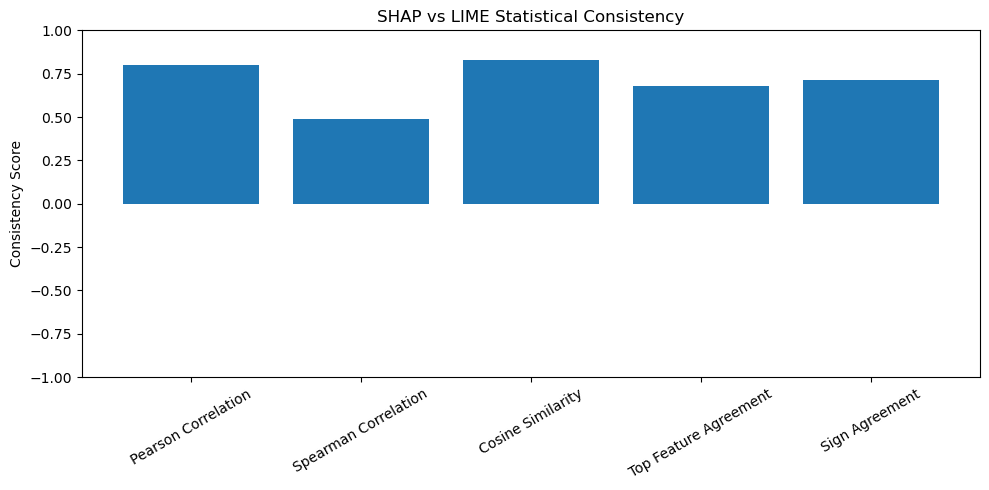

In [22]:


correlation_columns = [
    "Pearson Correlation",
    "Spearman Correlation",
    "Cosine Similarity",
    "Top Feature Agreement",
    "Sign Agreement"
]

correlation_means = [
    comparison_df[column].mean()
    for column in correlation_columns
]

plt.figure(figsize=(10, 5))

plt.bar(
    correlation_columns,
    correlation_means
)

plt.ylim(-1, 1)
plt.ylabel("Consistency Score")
plt.title("SHAP vs LIME Statistical Consistency")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


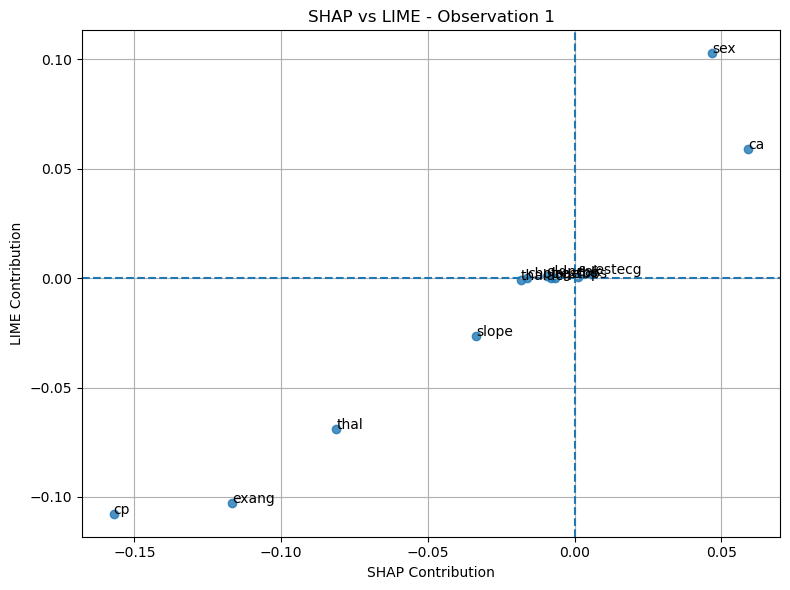

In [23]:

observation_number = 0

x_values = shap_results[observation_number]
y_values = lime_results[observation_number]

plt.figure(figsize=(8, 6))

plt.scatter(
    x_values,
    y_values,
    alpha=0.8
)

for j, feature in enumerate(feature_names):

    plt.annotate(
        feature,
        (x_values[j], y_values[j])
    )

plt.axhline(0, linestyle="--")
plt.axvline(0, linestyle="--")

plt.xlabel("SHAP Contribution")
plt.ylabel("LIME Contribution")

plt.title(
    f"SHAP vs LIME - Observation {observation_number + 1}"
)

plt.grid(True)
plt.tight_layout()
plt.show()



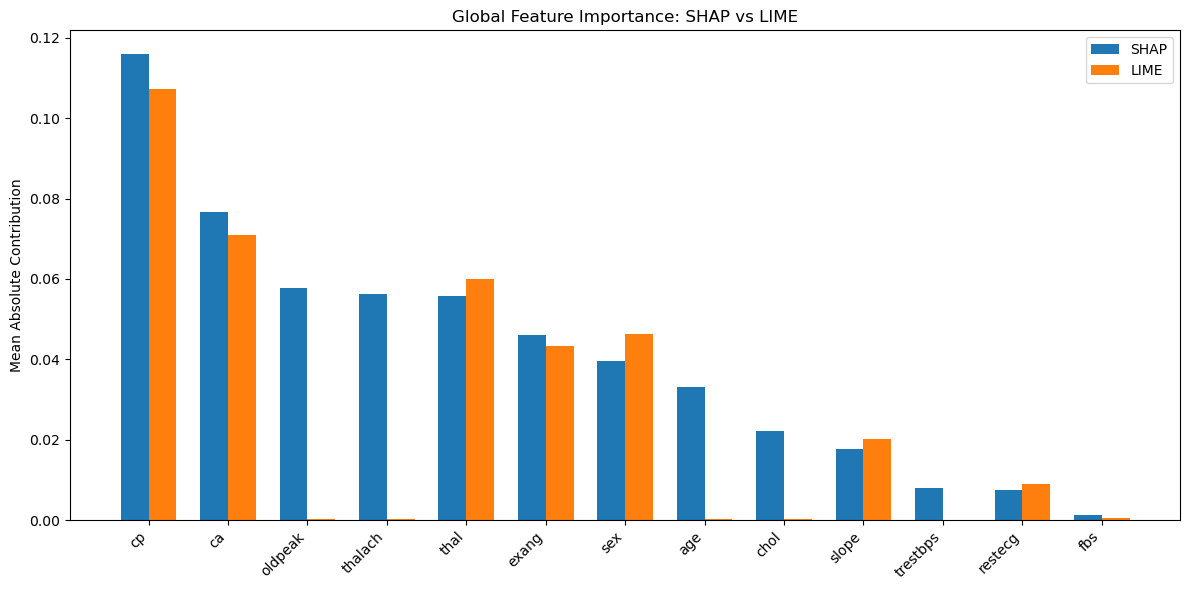

In [24]:


comparison_importance = pd.DataFrame({
    "Feature": feature_names,
    "SHAP Importance": np.mean(
        np.abs(shap_results),
        axis=0
    ),
    "LIME Importance": np.mean(
        np.abs(lime_results),
        axis=0
    )
})

comparison_importance = comparison_importance.sort_values(
    "SHAP Importance",
    ascending=False
)

plt.figure(figsize=(12, 6))

x = np.arange(len(feature_names))
width = 0.35

plt.bar(
    x - width / 2,
    comparison_importance["SHAP Importance"],
    width,
    label="SHAP"
)

plt.bar(
    x + width / 2,
    comparison_importance["LIME Importance"],
    width,
    label="LIME"
)

plt.xticks(
    x,
    comparison_importance["Feature"],
    rotation=45,
    ha="right"
)

plt.ylabel("Mean Absolute Contribution")
plt.title("Global Feature Importance: SHAP vs LIME")
plt.legend()
plt.tight_layout()
plt.show()



In [25]:


feature_consistency_df["Feature Type"] = [
    "Categorical" if j in categorical_features
    else "Continuous"
    for j in [
        feature_names.index(feature)
        for feature in feature_consistency_df["Feature"]
    ]
]

print("\nFEATURE TYPE CONSISTENCY")

type_summary = feature_consistency_df.groupby(
    "Feature Type"
)[
    [
        "SHAP Mean Absolute",
        "LIME Mean Absolute",
        "SHAP Variability",
        "LIME Variability",
        "Feature-wise Pearson",
        "Sign Agreement"
    ]
].mean()

print(type_summary.round(4))

type_summary.to_csv(
    "shap_lime_feature_type_comparison.csv"
)




FEATURE TYPE CONSISTENCY
              SHAP Mean Absolute  LIME Mean Absolute  SHAP Variability  \
Feature Type                                                             
Categorical               0.0451              0.0447            0.0473   
Continuous                0.0354              0.0002            0.0389   

              LIME Variability  Feature-wise Pearson  Sign Agreement  
Feature Type                                                          
Categorical             0.0456                0.8583          0.9125  
Continuous              0.0003               -0.1936          0.4000  


In [26]:


print("\nFINAL ANALYSIS")
print("--------------------------------")

print(
    "Average Pearson Correlation:",
    round(
        comparison_df["Pearson Correlation"].mean(),
        4
    )
)

print(
    "Average Spearman Correlation:",
    round(
        comparison_df["Spearman Correlation"].mean(),
        4
    )
)

print(
    "Average Cosine Similarity:",
    round(
        comparison_df["Cosine Similarity"].mean(),
        4
    )
)

print(
    "Average LIME Validation R2:",
    round(
        comparison_df["LIME Validation R2"].mean(),
        4
    )
)

print("\nAnalysis completed successfully.")



FINAL ANALYSIS
--------------------------------
Average Pearson Correlation: 0.8001
Average Spearman Correlation: 0.4885
Average Cosine Similarity: 0.8304
Average LIME Validation R2: 0.831

Analysis completed successfully.
